In [ ]:
%%writefile als_nested_validation.py
"""
Nested validation of the ALS 6-gene pipeline (GSE234297).

Your notebook picked the 6 genes using all 144 samples and then cross-validated.
Here the same recipe is repeated from scratch inside every training fold, and the
held-out samples are only used to score the finished model:

    DE test on training samples (BH padj < 0.05)
      -> intersect with the ME4 module            (mode "ME4")
      -> LASSO (C=0.1) and Random Forest top 20, keep the overlap
      -> Random Forest classifier on the overlap, scored on the held-out fold

Differences from the notebook:
  * DE is a Welch t-test on log2(normalised counts + 1), not PyDESeq2.
  * The ME4 gene list is fixed from the full dataset (rerunning WGCNA per fold
    is too slow), so mode "ME4" still leaks a little through the module choice.
    Mode "DEG only" has no module step and is the cleaner estimate.

Usage:
    python als_nested_validation.py NORMALIZED_COUNTS DESEQ2_FULL ME4_GENES PHENOTYPE [OUTDIR]
"""
import sys
import warnings
from collections import Counter

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
HUB6 = ["53829", "3480", "3772", "3660", "9466", "55350"]
SYMBOL = {"53829": "P2RY13", "3480": "IGF1R", "3772": "KCNJ15",
          "3660": "IRF2", "9466": "IL27RA", "55350": "VNN3P"}


def bh(p):
    p = np.asarray(p, float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(ranked, 1)
    return out


def metrics(y, prob):
    pred = (prob >= 0.5).astype(int)
    return dict(
        auc=roc_auc_score(y, prob),
        acc=float((pred == y).mean()),
        bal_acc=balanced_accuracy_score(y, pred),
        sens=float(((pred == 1) & (y == 1)).sum() / max((y == 1).sum(), 1)),
        spec=float(((pred == 0) & (y == 0)).sum() / max((y == 0).sum(), 1)),
    )


def select_and_score(Xtr, ytr, Xte, yte, genes, tested_idx, me4_set, mode):
    """Run the whole selection recipe on the training fold only."""
    t, p = stats.ttest_ind(Xtr[ytr == 1][:, tested_idx], Xtr[ytr == 0][:, tested_idx],
                           equal_var=False)
    p = np.nan_to_num(p, nan=1.0)
    padj = bh(p)
    tested_genes = genes[tested_idx]
    deg = tested_genes[padj < 0.05]
    cand = [g for g in deg if g in me4_set] if mode == "ME4" else list(deg)
    fallback = False
    if len(cand) < 5:                       # too few survivors: take the 20 best p-values
        fallback = True
        cand = list(tested_genes[np.argsort(p)[:20]])
    ci = [int(np.where(genes == g)[0][0]) for g in cand]

    sc = StandardScaler().fit(Xtr[:, ci])
    Ztr, Zte = sc.transform(Xtr[:, ci]), sc.transform(Xte[:, ci])

    lasso = LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                               max_iter=5000, random_state=SEED).fit(Ztr, ytr)
    lasso_sel = {cand[i] for i in np.flatnonzero(lasso.coef_[0])}
    rf = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1).fit(Ztr, ytr)
    top20 = [cand[i] for i in np.argsort(rf.feature_importances_)[::-1][:20]]
    hub = [g for g in top20 if g in lasso_sel]
    if not hub:                             # empty overlap: keep the 5 best RF genes
        fallback = True
        hub = top20[:5]
    hi = [cand.index(g) for g in hub]

    clf = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
    clf.fit(Ztr[:, hi], ytr)
    prob = clf.predict_proba(Zte[:, hi])[:, 1]
    return metrics(yte, prob), hub, len(deg), len(cand), fallback


def summarise(name, rows):
    df = pd.DataFrame(rows)
    print(f"{name:<44} AUC {df.auc.mean():.3f} ± {df.auc.std():.3f} | "
          f"acc {df.acc.mean():.3f} | bal.acc {df.bal_acc.mean():.3f} | "
          f"sens {df.sens.mean():.2f} | spec {df.spec.mean():.2f}")
    return df


if __name__ == "__main__":
    norm_p, deseq_p, me4_p, pheno_p = sys.argv[1:5]
    outdir = sys.argv[5] if len(sys.argv) > 5 else "."

    norm = pd.read_csv(norm_p, sep="\t", index_col=0)
    norm.columns = norm.columns.astype(str)
    res = pd.read_csv(deseq_p, sep="\t", index_col=0)
    res.index = res.index.astype(str)
    me4 = {l.strip() for l in open(me4_p) if l.strip()}
    pheno = pd.read_csv(pheno_p, sep="\t").set_index("sample")

    y = (pheno.loc[norm.index, "condition"] == "ALS").astype(int).to_numpy()
    X = np.log2(norm.to_numpy() + 1)
    genes = np.array(norm.columns)
    tested = set(res.index[res["padj"].notna()])
    tested_idx = np.array([i for i, g in enumerate(genes) if g in tested])
    print(f"{len(y)} samples ({y.sum()} ALS / {(y == 0).sum()} control); "
          f"{len(tested_idx)} genes with an adjusted p-value; {len(me4)} ME4 genes")
    print(f"Majority-class accuracy: {y.mean():.3f}\n")

    splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(X, y))

    # 1. Your notebook's protocol: the 6 genes were already chosen on all samples
    hub_idx = [int(np.where(genes == g)[0][0]) for g in HUB6]
    rows = []
    for tr, te in splits:
        sc = StandardScaler().fit(X[tr][:, hub_idx])
        clf = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
        clf.fit(sc.transform(X[tr][:, hub_idx]), y[tr])
        rows.append(metrics(y[te], clf.predict_proba(sc.transform(X[te][:, hub_idx]))[:, 1]))
    leaky = summarise("Notebook protocol (6 genes fixed beforehand)", rows)

    # 2 and 3. Selection redone inside each training fold
    out = {}
    for mode, label in (("ME4", "Nested, DEG ∩ ME4 module"), ("DEG", "Nested, DEG only (no module)")):
        rows, hubs, ndeg, ncand, nfb = [], [], [], [], 0
        for tr, te in splits:
            m, hub, nd, nc, fb = select_and_score(X[tr], y[tr], X[te], y[te], genes,
                                                  tested_idx, me4, mode)
            rows.append(m); hubs.append(hub); ndeg.append(nd); ncand.append(nc); nfb += fb
        out[mode] = (summarise(label, rows), hubs)
        print(f"    in-fold DEGs per fold: median {int(np.median(ndeg))}; "
              f"candidates entering LASSO/RF: median {int(np.median(ncand))}; "
              f"folds that needed a fallback: {nfb}/{len(splits)}")
        counts = Counter(g for h in hubs for g in h)
        print("    how often your six genes were re-selected: " +
              ", ".join(f"{SYMBOL[g]} {counts.get(g, 0)}/{len(splits)}" for g in HUB6))

    # 4. Label-shuffled control for the no-module version (should sit near 0.5)
    rng = np.random.default_rng(SEED)
    rows = []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
        yp = y.copy()
        yp[tr] = rng.permutation(y[tr])      # shuffle training labels only
        m, *_ = select_and_score(X[tr], yp[tr], X[te], y[te], genes, tested_idx, me4, "DEG")
        rows.append(m)
    summarise("Nested, DEG only, shuffled training labels", rows)

    leaky.assign(protocol="notebook").to_csv(f"{outdir}/validation_notebook_protocol.csv", index=False)
    out["ME4"][0].assign(protocol="nested_ME4").to_csv(f"{outdir}/validation_nested_ME4.csv", index=False)
    out["DEG"][0].assign(protocol="nested_DEG").to_csv(f"{outdir}/validation_nested_DEG.csv", index=False)

Writing als_nested_validation.py


In [ ]:
import sys
sys.argv = ["als_nested_validation.py",
            "GSE234297_normalized_counts.txt",
            "GSE234297_DESeq2_full_results.txt",
            "GSE234297_ME4_genes.txt",
            "GSE234297_phenotype.txt",
            "."]
exec(open("als_nested_validation.py").read())

144 samples (96 ALS / 48 control); 6704 genes with an adjusted p-value; 352 ME4 genes
Majority-class accuracy: 0.667

Notebook protocol (6 genes fixed beforehand) AUC 0.682 ± 0.107 | acc 0.679 | bal.acc 0.610 | sens 0.82 | spec 0.40
Nested, DEG ∩ ME4 module                     AUC 0.571 ± 0.119 | acc 0.632 | bal.acc 0.554 | sens 0.79 | spec 0.32
    in-fold DEGs per fold: median 1; candidates entering LASSO/RF: median 20; folds that needed a fallback: 10/15
    how often your six genes were re-selected: P2RY13 0/15, IGF1R 3/15, KCNJ15 0/15, IRF2 2/15, IL27RA 4/15, VNN3P 0/15
Nested, DEG only (no module)                 AUC 0.578 ± 0.113 | acc 0.637 | bal.acc 0.561 | sens 0.79 | spec 0.33
    in-fold DEGs per fold: median 1; candidates entering LASSO/RF: median 20; folds that needed a fallback: 10/15
    how often your six genes were re-selected: P2RY13 0/15, IGF1R 0/15, KCNJ15 0/15, IRF2 1/15, IL27RA 0/15, VNN3P 0/15
Nested, DEG only, shuffled training labels   AUC 0.376 ± 0.111 | acc 

In [ ]:
import numpy as np, pandas as pd
from scipy import stats

norm = pd.read_csv("GSE234297_normalized_counts.txt", sep="\t", index_col=0)
norm.columns = norm.columns.astype(str)
res = pd.read_csv("GSE234297_DESeq2_full_results.txt", sep="\t", index_col=0); res.index = res.index.astype(str)
me4 = [l.strip() for l in open("GSE234297_ME4_genes.txt") if l.strip()]
pheno = pd.read_csv("GSE234297_phenotype.txt", sep="\t").set_index("sample")
y = (pheno.loc[norm.index, "condition"] == "ALS").astype(int).to_numpy()
L = np.log2(norm + 1)
Z = (L - L.mean()) / L.std(ddof=0)

neut = ["2215", "1441", "3579", "6279", "6280"]   # FCGR3B, CSF3R, CXCR2, S100A8, S100A9
tcell = ["916", "915", "914", "3575"]              # CD3E, CD3D, CD2, IL7R
score = {"neutrophil": Z[neut].mean(axis=1).to_numpy(),
         "T_cell": Z[tcell].mean(axis=1).to_numpy(),
         "ME4_mean": Z[[g for g in me4 if g in Z.columns]].mean(axis=1).to_numpy()}
for k, v in score.items():
    p = stats.mannwhitneyu(v[y == 1], v[y == 0])[1]
    d = (v[y == 1].mean() - v[y == 0].mean()) / v.std()
    print(f"{k:<11} ALS vs control: standardized diff {d:+.2f}, p = {p:.3g}")
print("ME4 vs neutrophil r =", round(np.corrcoef(score["ME4_mean"], score["neutrophil"])[0, 1], 2))
print("ME4 vs T-cell r     =", round(np.corrcoef(score["ME4_mean"], score["T_cell"])[0, 1], 2))

def cond_p(Y, covs):
    X = np.column_stack([np.ones(len(y)), y] + covs)
    XtXi = np.linalg.inv(X.T @ X)
    B = XtXi @ X.T @ Y
    s2 = ((Y - X @ B) ** 2).sum(0) / (X.shape[0] - X.shape[1])
    t = B[1] / np.sqrt(s2 * XtXi[1, 1])
    return 2 * stats.t.sf(np.abs(t), X.shape[0] - X.shape[1])

deg = [g for g in res.index[res.padj < 0.05] if g in L.columns]
sets = {"290 DEGs": deg, "100 DEG∩ME4": [g for g in deg if g in me4],
        "six genes": ["53829", "3480", "3772", "3660", "9466", "55350"]}
for name, genes in sets.items():
    Y = L[genes].to_numpy()
    p0 = cond_p(Y, [])
    p1 = cond_p(Y, [score["neutrophil"], score["T_cell"]])
    print(f"{name}: p<0.05 before {int((p0 < 0.05).sum())}/{len(genes)}, after adjusting {int((p1 < 0.05).sum())}/{len(genes)}")

neutrophil  ALS vs control: standardized diff +0.56, p = 0.00116
T_cell      ALS vs control: standardized diff -0.30, p = 0.0602
ME4_mean    ALS vs control: standardized diff +0.55, p = 0.00178
ME4 vs neutrophil r = 0.63
ME4 vs T-cell r     = -0.56
290 DEGs: p<0.05 before 287/290, after adjusting 170/290
100 DEG∩ME4: p<0.05 before 100/100, after adjusting 43/100
six genes: p<0.05 before 6/6, after adjusting 6/6


In [ ]:
!pip install GEOparse -q
import GEOparse, pandas as pd
gse = GEOparse.get_GEO("GSE234297", destdir=".", silent=True)
rows = []
for name, gsm in gse.gsms.items():
    row = {"gsm": name, "title": gsm.metadata.get("title", [""])[0]}
    for ch in gsm.metadata.get("characteristics_ch1", []):
        k, _, v = ch.partition(":")
        row[k.strip().lower()] = v.strip()
    rows.append(row)
meta = pd.DataFrame(rows)
print(meta.shape); print(meta.head(10).to_string())

(144, 4)
          gsm                   title            tissue disease state
0  GSM7461691  PeripheralBlood_Case01  peripheral blood          sALS
1  GSM7461692  PeripheralBlood_Case02  peripheral blood          sALS
2  GSM7461693  PeripheralBlood_Case03  peripheral blood          sALS
3  GSM7461694  PeripheralBlood_Case04  peripheral blood          sALS
4  GSM7461695  PeripheralBlood_Case05  peripheral blood          sALS
5  GSM7461696  PeripheralBlood_Case06  peripheral blood          sALS
6  GSM7461697  PeripheralBlood_Case07  peripheral blood          sALS
7  GSM7461698  PeripheralBlood_Case08  peripheral blood          sALS
8  GSM7461699  PeripheralBlood_Case09  peripheral blood          sALS
9  GSM7461700  PeripheralBlood_Case10  peripheral blood          sALS


In [ ]:
!pip install -q "pandas==2.3.3" "pydeseq2==0.4.12"


In [ ]:
import pydeseq2
print(pydeseq2.__version__)

0.4.12


In [ ]:
!pip install -q "anndata==0.10.9"

In [ ]:
import pydeseq2, anndata
print(pydeseq2.__version__, anndata.__version__)

0.4.12 0.10.9


In [ ]:
import pandas as pd, numpy as np
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

meta = pd.read_excel("NAN-49-0-s002.xlsx", header=5).set_index("Collection_ID")
counts = pd.read_csv("GSE234297_gene_raw_counts_rounded.txt", sep="\t", index_col=0)
counts.index = counts.index.astype(str)
counts = counts.T                                   # samples x genes
meta = meta.loc[counts.index]

md = pd.DataFrame({
    "condition": np.where(meta.Disease_status == "sALS", "ALS", "Control"),
    "sex": meta.Sex.values,
    "age": ((meta.Age_at_collection - meta.Age_at_collection.mean()) / meta.Age_at_collection.std()).values,
    "flowcell": meta.Flowcell_ID.str[:6].values,
}, index=counts.index)

counts = counts.loc[:, (counts >= 10).sum(axis=0) >= 0.1 * len(counts)]   # same style of filter as before

dds = DeseqDataSet(counts=counts, metadata=md, design_factors=["sex", "age", "flowcell", "condition"])
dds.deseq2()
st = DeseqStats(dds, contrast=["condition", "ALS", "Control"])
st.summary()
adj = st.results_df
adj.to_csv("GSE234297_DESeq2_adjusted.txt", sep="\t")

old = pd.read_csv("GSE234297_DESeq2_full_results.txt", sep="\t", index_col=0)
old.index = old.index.astype(str)
sig_old = set(old.index[old.padj < 0.05]); sig_new = set(adj.index[adj.padj < 0.05])
print("unadjusted DEGs:", len(sig_old), "| adjusted DEGs:", len(sig_new), "| shared:", len(sig_old & sig_new))
hub = {"53829":"P2RY13","3480":"IGF1R","3772":"KCNJ15","3660":"IRF2","9466":"IL27RA","55350":"VNN3P"}
print(adj.loc[[g for g in hub if g in adj.index], ["log2FoldChange","padj"]].rename(index=hub))

Fitting size factors...
... done in 0.09 seconds.

Fitting dispersions...
... done in 319.98 seconds.

Fitting dispersion trend curve...
... done in 0.42 seconds.

Fitting MAP dispersions...
... done in 199.58 seconds.

Fitting LFCs...
... done in 193.36 seconds.

Calculating cook's distance...
... done in 0.16 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 20.87 seconds.



Log2 fold change & Wald test p-value: condition ALS vs Control
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EntrezGeneID                                                             
1              20.806203       -0.318146  0.380318 -0.836527  0.402859   
9               8.617032       -0.147663  0.463659 -0.318472  0.750127   
14            331.465075       -0.297634  0.155336 -1.916068  0.055356   
16            189.981399       -0.130109  0.182520 -0.712849  0.475939   
18             72.827421        0.311609  0.258891  1.203631  0.228732   
...                  ...             ...       ...       ...       ...   
114483834      56.649854        0.043420  0.264695  0.164039  0.869701   
114841035      27.353942       -0.024780  0.331527 -0.074746  0.940417   
115253422      25.379782       -0.263195  0.292656 -0.899332  0.368476   
115804232      97.161756       -0.697338  0.252585 -2.760799  0.005766   
115830329      28.130740        0.105651  0.25365

In [ ]:
import pandas as pd, numpy as np
from scipy.stats import spearmanr
adj = pd.read_csv("GSE234297_DESeq2_adjusted.txt", sep="\t", index_col=0); adj.index = adj.index.astype(str)
old = pd.read_csv("GSE234297_DESeq2_full_results.txt", sep="\t", index_col=0); old.index = old.index.astype(str)
sh = adj.index.intersection(old.index)
print("genes in both:", len(sh))
print("Spearman of Wald stat, old vs adjusted:", spearmanr(old.loc[sh,"stat"], adj.loc[sh,"stat"], nan_policy="omit")[0])
degs = old.index[old.padj < 0.05].intersection(adj.index)
print("old DEGs present in adjusted run:", len(degs))
print("  same direction:", (np.sign(old.loc[degs,"log2FoldChange"]) == np.sign(adj.loc[degs,"log2FoldChange"])).sum())
print("  nominal p<0.05 after adjustment:", (adj.loc[degs,"pvalue"] < 0.05).sum())

genes in both: 14198
Spearman of Wald stat, old vs adjusted: 0.7229567533749082
old DEGs present in adjusted run: 290
  same direction: 290
  nominal p<0.05 after adjustment: 144


In [ ]:
import pandas as pd, numpy as np
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

meta = pd.read_excel("NAN-49-0-s002.xlsx", header=5).set_index("Collection_ID")
counts = pd.read_csv("GSE234297_gene_raw_counts_rounded.txt", sep="\t", index_col=0)
counts.index = counts.index.astype(str)
counts = counts.T
meta = meta.loc[counts.index]

md = pd.DataFrame({"condition": np.where(meta.Disease_status == "sALS", "ALS", "Control")}, index=counts.index)
counts = counts.loc[:, (counts >= 10).sum(axis=0) >= 0.1 * len(counts)]   # same filter as the adjusted run
print(counts.shape, md.condition.value_counts().to_dict())

dds0 = DeseqDataSet(counts=counts, metadata=md, design_factors=["condition"])
dds0.deseq2()
st0 = DeseqStats(dds0, contrast=["condition", "ALS", "Control"]); st0.summary()
base = st0.results_df
base.to_csv("GSE234297_DESeq2_condition_only_samefilter.txt", sep="\t")
print("condition-only, same filter: DEGs =", (base.padj < 0.05).sum())

(144, 14198) {'ALS': 96, 'Control': 48}


Fitting size factors...
... done in 0.10 seconds.

Fitting dispersions...
... done in 28.26 seconds.

Fitting dispersion trend curve...
... done in 0.58 seconds.

Fitting MAP dispersions...
... done in 36.64 seconds.

Fitting LFCs...
... done in 15.97 seconds.

Calculating cook's distance...
... done in 0.13 seconds.

Replacing 62 outlier genes.

Fitting dispersions...
... done in 0.18 seconds.

Fitting MAP dispersions...
... done in 0.18 seconds.

Fitting LFCs...
... done in 0.13 seconds.

Running Wald tests...
... done in 3.40 seconds.



Log2 fold change & Wald test p-value: condition ALS vs Control
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EntrezGeneID                                                             
1              20.806203       -0.171292  0.151237 -1.132605  0.257380   
9               8.617032        0.211541  0.165601  1.277413  0.201456   
14            331.465075       -0.158741  0.056941 -2.787841  0.005306   
16            189.981399       -0.140073  0.063518 -2.205239  0.027437   
18             72.827421        0.093223  0.099685  0.935182  0.349694   
...                  ...             ...       ...       ...       ...   
114483834      56.649854       -0.023537  0.112710 -0.208829  0.834582   
114841035      27.353942       -0.191001  0.150516 -1.268981  0.204448   
115253422      25.379782        0.066616  0.124134  0.536646  0.591512   
115804232      97.161756       -0.245242  0.140650 -1.743628  0.081224   
115830329      28.130740        0.082611  0.08466

In [ ]:
import pandas as pd, numpy as np
from pydeseq2.dds import DeseqDataSet

meta = pd.read_excel("NAN-49-0-s002.xlsx", header=5).set_index("Collection_ID")
counts = pd.read_csv("GSE234297_gene_raw_counts_rounded.txt", sep="\t", index_col=0)
counts.index = counts.index.astype(str); counts = counts.T; meta = meta.loc[counts.index]
counts = counts.loc[:, (counts >= 10).sum(axis=0) >= 0.1 * len(counts)]

md = pd.DataFrame({
    "condition": np.where(meta.Disease_status == "sALS", "ALS", "Control"),
    "sex": meta.Sex.values,
    "age": ((meta.Age_at_collection - meta.Age_at_collection.mean()) / meta.Age_at_collection.std()).values,
    "flowcell": meta.Flowcell_ID.str[:6].values,
}, index=counts.index)

dds = DeseqDataSet(counts=counts, metadata=md, design_factors=["sex", "age", "flowcell", "condition"])
X = dds.obsm["design_matrix"]
print(X.columns.tolist())
print(X.dtypes.value_counts().to_dict())
print("rank:", np.linalg.matrix_rank(X.to_numpy(dtype=float)), "of", X.shape[1], "| condition number:", np.linalg.cond(X.to_numpy(dtype=float)))
print(X.describe().T[["mean", "std", "min", "max"]])

['intercept', 'sex_M_vs_F', 'age_-0.0888825757275473_vs_-0.043682725563568045', 'age_-0.0964158840882106_vs_-0.043682725563568045', 'age_-0.11901580917019995_vs_-0.043682725563568045', 'age_-0.1491490426128526_vs_-0.043682725563568045', 'age_-0.16421565933417923_vs_-0.043682725563568045', 'age_-0.17928227605550529_vs_-0.043682725563568045', 'age_-0.19434889277683187_vs_-0.043682725563568045', 'age_-0.2320154345801478_vs_-0.043682725563568045', 'age_-0.25461535966213716_vs_-0.043682725563568045', 'age_-0.2696819763834638_vs_-0.043682725563568045', 'age_-0.314881826547443_vs_-0.043682725563568045', 'age_-0.32241513490810636_vs_-0.043682725563568045', 'age_-0.3299484432687691_vs_-0.043682725563568045', 'age_-0.3374817516294324_vs_-0.043682725563568045', 'age_-0.37514829343274836_vs_-0.043682725563568045', 'age_-0.38268160179341165_vs_-0.043682725563568045', 'age_-0.4128148352360643_vs_-0.043682725563568045', 'age_-0.44294806867871694_vs_-0.043682725563568045', 'age_-0.4655479937607069_vs_

In [ ]:
import pandas as pd, numpy as np
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

meta = pd.read_excel("NAN-49-0-s002.xlsx", header=5).set_index("Collection_ID")
counts = pd.read_csv("GSE234297_gene_raw_counts_rounded.txt", sep="\t", index_col=0)
counts.index = counts.index.astype(str); counts = counts.T; meta = meta.loc[counts.index]
counts = counts.loc[:, (counts >= 10).sum(axis=0) >= 0.1 * len(counts)]

md = pd.DataFrame({
    "condition": np.where(meta.Disease_status == "sALS", "ALS", "Control"),
    "sex": meta.Sex.values,
    "age_bin": pd.cut(meta.Age_at_collection, [0, 50, 60, 70, 80, 120],
                      labels=["lt50", "50s", "60s", "70s", "80plus"]).astype(str).values,
    "flowcell": meta.Flowcell_ID.str[:6].values,
}, index=counts.index)
print(md.age_bin.value_counts().to_dict())

dds = DeseqDataSet(counts=counts, metadata=md,
                   design_factors=["sex", "age_bin", "flowcell", "condition"])
print("design columns:", dds.obsm["design_matrix"].shape[1])   # should be about 9, not 130
dds.deseq2()
st = DeseqStats(dds, contrast=["condition", "ALS", "Control"]); st.summary()
adj = st.results_df
adj.to_csv("GSE234297_DESeq2_adjusted_v2.txt", sep="\t")

base = pd.read_csv("GSE234297_DESeq2_condition_only_samefilter.txt", sep="\t", index_col=0)
base.index = base.index.astype(str); adj.index = adj.index.astype(str)
sb, sa = set(base.index[base.padj < 0.05]), set(adj.index[adj.padj < 0.05])
print("condition-only DEGs:", len(sb), "| adjusted DEGs:", len(sa), "| shared:", len(sb & sa))
hub = {"53829": "P2RY13", "3480": "IGF1R", "3772": "KCNJ15", "3660": "IRF2", "9466": "IL27RA", "55350": "VNN3P"}
print(adj.loc[[g for g in hub if g in adj.index], ["log2FoldChange", "lfcSE", "padj"]].rename(index=hub))

{'60s': 45, '70s': 35, 'lt50': 28, '50s': 24, '80plus': 12}


/tmp/ipykernel_73990/3876890218.py:19: UserWarning: Same factor names in the design contain underscores ('_'). They will
                be converted to hyphens ('-').
  dds = DeseqDataSet(counts=counts, metadata=md,
Fitting size factors...
... done in 0.10 seconds.



design columns: 9


Fitting dispersions...
... done in 34.96 seconds.

Fitting dispersion trend curve...
... done in 0.82 seconds.

Fitting MAP dispersions...
... done in 39.02 seconds.

Fitting LFCs...
... done in 21.74 seconds.

Calculating cook's distance...
... done in 0.20 seconds.

Replacing 4 outlier genes.

Fitting dispersions...
... done in 0.03 seconds.

Fitting MAP dispersions...
... done in 0.03 seconds.

Fitting LFCs...
... done in 0.04 seconds.

Running Wald tests...
... done in 4.78 seconds.



Log2 fold change & Wald test p-value: condition ALS vs Control
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EntrezGeneID                                                             
1              20.806203       -0.219800  0.138115 -1.591422  0.111515   
9               8.617032        0.206072  0.166947  1.234354  0.217071   
14            331.465075       -0.182733  0.054633 -3.344730  0.000824   
16            189.981399       -0.130577  0.062749 -2.080941  0.037439   
18             72.827421        0.081131  0.102624  0.790564  0.429198   
...                  ...             ...       ...       ...       ...   
114483834      56.649854       -0.020969  0.114731 -0.182765  0.854983   
114841035      27.353942       -0.220045  0.149690 -1.470004  0.141561   
115253422      25.379782        0.049335  0.125162  0.394164  0.693460   
115804232      97.161756       -0.237748  0.139814 -1.700462  0.089044   
115830329      28.130740        0.104870  0.08572

In [ ]:
import pandas as pd, numpy as np
from scipy.stats import hypergeom

adj = pd.read_csv("GSE234297_DESeq2_adjusted_v2.txt", sep="\t", index_col=0); adj.index = adj.index.astype(str)
me4 = {l.strip() for l in open("GSE234297_ME4_genes.txt") if l.strip()}
norm = pd.read_csv("GSE234297_normalized_counts.txt", sep="\t", index_col=0); norm.columns = norm.columns.astype(str)
bg = set(norm.var(axis=0).sort_values(ascending=False).head(5000).index)   # same top-5000 as your WGCNA

deg = set(adj.index[adj.padj < 0.05]) & bg
m = me4 & bg
inter = deg & m
exp = len(deg) * len(m) / len(bg)
p = hypergeom.sf(len(inter) - 1, len(bg), len(m), len(deg))
print(f"DEGs in background: {len(deg)} | ME4 genes in background: {len(m)} | overlap: {len(inter)} | expected by chance: {exp:.1f} | hypergeometric p: {p:.2e}")
hub = {"53829","3480","3772","3660","9466","55350"}
print("six genes in the new overlap:", sorted(hub & inter))
pd.Series(sorted(inter)).to_csv("DEG_adjusted_ME4_overlap.txt", index=False, header=False)

DEGs in background: 249 | ME4 genes in background: 352 | overlap: 86 | expected by chance: 17.5 | hypergeometric p: 5.65e-40
six genes in the new overlap: ['3480', '3660', '3772', '53829', '55350', '9466']


In [ ]:
!pip install -q gprofiler-official
import pandas as pd
from gprofiler import GProfiler

adj = pd.read_csv("GSE234297_DESeq2_adjusted_v2.txt", sep="\t", index_col=0); adj.index = adj.index.astype(str)
query = [l.strip() for l in open("DEG_adjusted_ME4_overlap.txt") if l.strip()]
background = adj.index[adj.padj.notna()].tolist()   # genes that were actually tested (independent filtering applied)

gp = GProfiler(return_dataframe=True)
res = gp.profile(organism="hsapiens", query=query, background=background, domain_scope="custom",
                 sources=["GO:BP", "KEGG", "REAC"], user_threshold=0.05,
                 significance_threshold_method="g_SCS", no_evidences=True)
cols = ["source", "native", "name", "p_value", "intersection_size", "term_size"]
print(res[cols].head(20).to_string())
res[cols].to_csv("enrichment_overlap86.csv", index=False)

  source      native                                       name   p_value  intersection_size  term_size
0  GO:BP  GO:0043086  negative regulation of catalytic activity  0.011323                 11        132


In [ ]:
up = adj.loc[[g for g in query if g in adj.index]]
up_ids = up.index[up.log2FoldChange > 0].tolist(); down_ids = up.index[up.log2FoldChange < 0].tolist()
print("up in ALS:", len(up_ids), "| down in ALS:", len(down_ids))

for label, ids in [("UP", up_ids), ("DOWN", down_ids)]:
    r = gp.profile(organism="hsapiens", query=ids, background=background, domain_scope="custom",
                   sources=["GO:BP", "KEGG", "REAC"], user_threshold=0.05,
                   significance_threshold_method="g_SCS", no_evidences=True)
    print(f"\n--- {label}, tested-gene background ---"); print(r[cols].head(8).to_string() if len(r) else "no terms")

r = gp.profile(organism="hsapiens", query=query, sources=["GO:BP", "KEGG", "REAC"], user_threshold=0.05,
               significance_threshold_method="g_SCS", no_evidences=True)
print("\n--- all 86, whole-genome background ---"); print(r[cols].head(10).to_string() if len(r) else "no terms")

up in ALS: 78 | down in ALS: 8

--- UP, tested-gene background ---
  source      native                                       name   p_value  intersection_size  term_size
0  GO:BP  GO:0043086  negative regulation of catalytic activity  0.039357                 10        132

--- DOWN, tested-gene background ---
no terms

--- all 86, whole-genome background ---
  source             native                                                     name   p_value  intersection_size  term_size
0  GO:BP         GO:0043086                negative regulation of catalytic activity  0.000002                 11        233
1  GO:BP         GO:0048518                positive regulation of biological process  0.000005                 49       6150
2   REAC  REAC:R-HSA-168256                                            Immune System  0.000007                 31       2086
3  GO:BP         GO:0044092                negative regulation of molecular function  0.000018                 12        355
4  GO:BP    

next

In [2]:
!pip install GEOparse -q
import GEOparse, pandas as pd
gse = GEOparse.get_GEO("GSE112680", destdir=".", silent=True)
print("platforms:", list(gse.gpls.keys()))
rows = []
for name, gsm in gse.gsms.items():
    row = {"gsm": name, "title": gsm.metadata.get("title", [""])[0]}
    for ch in gsm.metadata.get("characteristics_ch1", []):
        k, _, v = ch.partition(":")
        row[k.strip().lower()] = v.strip()
    rows.append(row)
meta = pd.DataFrame(rows)
print(meta.shape)
print(meta.head(10).to_string())
for c in meta.columns[2:]:
    if meta[c].nunique() < 12:
        print("\n", c, meta[c].value_counts().to_dict())

platforms: ['GPL10558']
(376, 8)
          gsm                                         title sex diagnosis site_onset age_onset       survival_yr censored
0  GSM3079737  whole blood gene expression profile_ALS03718   m       MIM         NA        NA                NA       NA
1  GSM3079740  whole blood gene expression profile_ALS03729   m       ALS          s     59.27  4.89427104722792        1
2  GSM3079742  whole blood gene expression profile_ALS05873   v       ALS          s     69.84  1.47279945242984        0
3  GSM3079744  whole blood gene expression profile_ALS07130   v       CON         NA        NA                NA       NA
4  GSM3079746  whole blood gene expression profile_ALS04157   m       MIM         NA        NA                NA        0
5  GSM3079749  whole blood gene expression profile_ALS03901   m       ALS          s     45.62  4.41696098562629        0
6  GSM3079751  whole blood gene expression profile_ALS05882   m       ALS          s     70.73  3.73680355920602 

In [3]:
import numpy as np, pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# 1. external expression matrix and probe-to-gene map
expr = gse.pivot_samples("VALUE")                       # probes x samples
gpl = gse.gpls["GPL10558"].table.set_index("ID")
print("annotation columns:", gpl.columns.tolist())
print("value range:", float(expr.min().min()), float(expr.max().max()))
if expr.max().max() > 100:                              # already log2 on Illumina arrays; this only fires if it is not
    expr = np.log2(expr.clip(lower=1))

HUB = {"53829": "P2RY13", "3480": "IGF1R", "3772": "KCNJ15", "3660": "IRF2", "9466": "IL27RA", "55350": "VNN3P"}
idcol = "Entrez_Gene_ID" if "Entrez_Gene_ID" in gpl.columns else None
symcol = "Symbol" if "Symbol" in gpl.columns else "ILMN_Gene"
ext = {}
for eid, sym in HUB.items():
    mask = (gpl[idcol].astype(str).str.split(".").str[0] == eid) if idcol else (gpl[symcol] == sym)
    probes = [p for p in gpl.index[mask] if p in expr.index]
    print(f"{sym:<8} probes on array: {len(probes)}")
    if probes: ext[eid] = expr.loc[probes].mean(axis=0)
E = pd.DataFrame(ext)                                   # samples x available genes
avail = list(E.columns)
print("genes available:", [HUB[g] for g in avail])

# 2. frozen model trained on the discovery cohort only
norm = pd.read_csv("GSE234297_normalized_counts.txt", sep="\t", index_col=0); norm.columns = norm.columns.astype(str)
yd = np.array([1 if s.startswith("Case") else 0 for s in norm.index])
Xd = np.log2(norm[avail] + 1); Xd = (Xd - Xd.mean()) / Xd.std()
rf = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1).fit(Xd, yd)

# 3. score the external cohort (z-scored within itself, because the platforms differ)
Z = (E - E.mean()) / E.std()
dx = meta.set_index("gsm").loc[E.index, "diagnosis"]
prob = pd.Series(rf.predict_proba(Z[avail])[:, 1], index=E.index)
sign = {"53829": 1, "3480": 1, "3772": 1, "3660": 1, "55350": 1, "9466": -1}
simple = sum(sign[g] * Z[g] for g in avail)

def auc(score, a, b):
    m = dx.isin([a, b]); return roc_auc_score((dx[m] == a).astype(int), score[m])
print(f"\nRF (frozen): ALS vs CON AUC {auc(prob,'ALS','CON'):.3f} | ALS vs MIM AUC {auc(prob,'ALS','MIM'):.3f}")
print(f"Simple signed z-score: ALS vs CON AUC {auc(simple,'ALS','CON'):.3f} | ALS vs MIM AUC {auc(simple,'ALS','MIM'):.3f}")

print("\nPer gene (mean z in ALS minus CON, Welch p):")
for g in avail:
    a, c = Z.loc[dx == "ALS", g], Z.loc[dx == "CON", g]
    print(f"{HUB[g]:<8} expected {'up' if sign[g] > 0 else 'down'} | diff {a.mean()-c.mean():+.2f} | p = {stats.ttest_ind(a, c, equal_var=False)[1]:.3g}")

annotation columns: ['Species', 'Source', 'Search_Key', 'Transcript', 'ILMN_Gene', 'Source_Reference_ID', 'RefSeq_ID', 'Unigene_ID', 'Entrez_Gene_ID', 'GI', 'Accession', 'Symbol', 'Protein_Product', 'Probe_Id', 'Array_Address_Id', 'Probe_Type', 'Probe_Start', 'SEQUENCE', 'Chromosome', 'Probe_Chr_Orientation', 'Probe_Coordinates', 'Cytoband', 'Definition', 'Ontology_Component', 'Ontology_Process', 'Ontology_Function', 'Synonyms', 'Obsolete_Probe_Id', 'GB_ACC']
value range: 6.23662507590481 14.6428073832044
P2RY13   probes on array: 3
IGF1R    probes on array: 1
KCNJ15   probes on array: 3
IRF2     probes on array: 2
IL27RA   probes on array: 1
VNN3P    probes on array: 3
genes available: ['P2RY13', 'IGF1R', 'KCNJ15', 'IRF2', 'IL27RA', 'VNN3P']

RF (frozen): ALS vs CON AUC 0.597 | ALS vs MIM AUC 0.612
Simple signed z-score: ALS vs CON AUC 0.611 | ALS vs MIM AUC 0.661

Per gene (mean z in ALS minus CON, Welch p):
P2RY13   expected up | diff -0.02 | p = 0.842
IGF1R    expected up | diff +0

In [4]:
rng = np.random.default_rng(0)
m = dx.isin(["ALS", "CON"]).to_numpy()
y = (dx[m] == "ALS").astype(int).to_numpy(); p = prob[m].to_numpy()
boots = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    if y[i].min() != y[i].max(): boots.append(roc_auc_score(y[i], p[i]))
print("RF ALS vs CON AUC 95% CI:", np.percentile(boots, [2.5, 97.5]).round(3))

for drop in avail:
    keep = [g for g in avail if g != drop]
    rf2 = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1).fit(Xd[keep], yd)
    pr = pd.Series(rf2.predict_proba(Z[keep])[:, 1], index=E.index)
    print(f"without {HUB[drop]:<7} AUC ALS vs CON {auc(pr, 'ALS', 'CON'):.3f}")

sel = gpl[gpl.Symbol.isin(["VNN1", "VNN2", "VNN3P", "VNN3"]) | gpl.Entrez_Gene_ID.astype(str).str.startswith("55350")]
print(sel[["Symbol", "ILMN_Gene", "Entrez_Gene_ID", "Definition", "Probe_Type"]].to_string())

RF ALS vs CON AUC 95% CI: [0.53  0.659]
without P2RY13  AUC ALS vs CON 0.609
without IGF1R   AUC ALS vs CON 0.574
without KCNJ15  AUC ALS vs CON 0.583
without IRF2    AUC ALS vs CON 0.569
without IL27RA  AUC ALS vs CON 0.592
without VNN3P   AUC ALS vs CON 0.594
             Symbol ILMN_Gene  Entrez_Gene_ID                                                Definition Probe_Type
ID                                                                                                                
ILMN_1674574   VNN1      VNN1          8876.0                        Homo sapiens vanin 1 (VNN1), mRNA.          S
ILMN_1678939   VNN2      VNN2          8875.0  Homo sapiens vanin 2 (VNN2), transcript variant 1, mRNA.          A
ILMN_1692546   VNN2      VNN2          8875.0  Homo sapiens vanin 2 (VNN2), transcript variant 2, mRNA.          I
ILMN_1702842   VNN3      VNN3         55350.0  Homo sapiens vanin 3 (VNN3), transcript variant 2, mRNA.          I
ILMN_1758864   VNN2      VNN2          8875.0  H

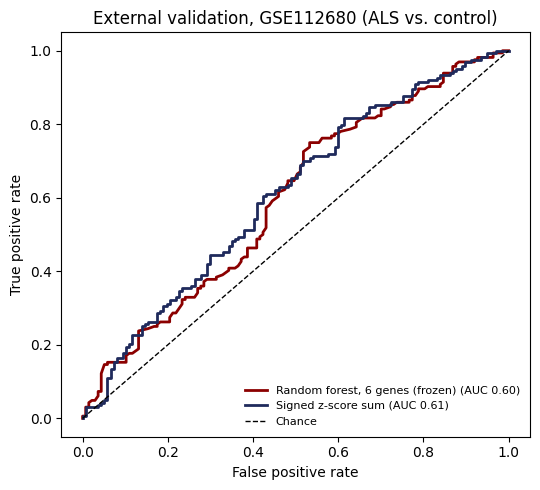

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5.5, 5))
for label, score, color in [("Random forest, 6 genes (frozen)", prob, "#8B0000"),
                            ("Signed z-score sum", simple, "#1F2A5C")]:
    m = dx.isin(["ALS", "CON"]).to_numpy()
    yy = (dx[m] == "ALS").astype(int).to_numpy()
    fpr, tpr, _ = roc_curve(yy, score[m].to_numpy())
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC {roc_auc_score(yy, score[m].to_numpy()):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("External validation, GSE112680 (ALS vs. control)")
ax.legend(loc="lower right", fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig("roc_external.png", dpi=200)

next

In [8]:
!pip install -q "pandas==2.3.3" "pydeseq2==0.4.12" "anndata==0.10.9"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.


In [9]:
import pandas as pd, numpy as np
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

meta_s1 = pd.read_excel("NAN-49-0-s002.xlsx", header=5).set_index("Collection_ID")
counts = pd.read_csv("GSE234297_gene_raw_counts_rounded.txt", sep="\t", index_col=0)
counts.index = counts.index.astype(str); counts = counts.T; meta_s1 = meta_s1.loc[counts.index]
counts = counts.loc[:, (counts >= 10).sum(axis=0) >= 0.1 * len(counts)]

md = pd.DataFrame({
    "condition": np.where(meta_s1.Disease_status == "sALS", "ALS", "Control"),
    "sex": meta_s1.Sex.values,
    "agebin": pd.cut(meta_s1.Age_at_collection, [0, 50, 60, 70, 80, 120],
                     labels=["lt50", "s50", "s60", "s70", "s80plus"]).astype(str).values,
    "flowcell": meta_s1.Flowcell_ID.str[:6].values,
}, index=counts.index)

dds = DeseqDataSet(counts=counts, metadata=md, design_factors=["sex", "agebin", "flowcell", "condition"])
print("design columns:", dds.obsm["design_matrix"].shape[1])          # should be 9
dds.deseq2()
st = DeseqStats(dds, contrast=["condition", "ALS", "Control"]); st.summary()
adj = st.results_df
adj.to_csv("GSE234297_DESeq2_adjusted_v2.txt", sep="\t")
print("adjusted DEGs (padj<0.05):", int((adj.padj < 0.05).sum()))      # should be 324

design columns: 9


Fitting size factors...
... done in 0.25 seconds.

Fitting dispersions...
... done in 21.04 seconds.

Fitting dispersion trend curve...
... done in 0.39 seconds.

Fitting MAP dispersions...
... done in 24.66 seconds.

Fitting LFCs...
... done in 16.20 seconds.

Calculating cook's distance...
... done in 0.12 seconds.

Replacing 4 outlier genes.

Fitting dispersions...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.02 seconds.

Running Wald tests...
... done in 2.80 seconds.



Log2 fold change & Wald test p-value: condition ALS vs Control
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EntrezGeneID                                                             
1              20.806203       -0.219800  0.138115 -1.591422  0.111515   
9               8.617032        0.206072  0.166947  1.234354  0.217071   
14            331.465075       -0.182733  0.054633 -3.344730  0.000824   
16            189.981399       -0.130577  0.062749 -2.080941  0.037439   
18             72.827421        0.081131  0.102624  0.790564  0.429198   
...                  ...             ...       ...       ...       ...   
114483834      56.649854       -0.020969  0.114731 -0.182765  0.854983   
114841035      27.353942       -0.220045  0.149690 -1.470004  0.141561   
115253422      25.379782        0.049335  0.125162  0.394164  0.693460   
115804232      97.161756       -0.237748  0.139814 -1.700462  0.089044   
115830329      28.130740        0.104870  0.08572

In [14]:
!pip install GEOparse -q
import GEOparse, numpy as np, pandas as pd

gse = GEOparse.get_GEO("GSE112680", destdir=".", silent=True)
rows = []
for name, gsm in gse.gsms.items():
    row = {"gsm": name}
    for ch in gsm.metadata.get("characteristics_ch1", []):
        k, _, v = ch.partition(":"); row[k.strip().lower()] = v.strip()
    rows.append(row)
meta = pd.DataFrame(rows)

expr = gse.pivot_samples("VALUE")                      # probes x samples (already log2 for this Illumina array)
gpl = gse.gpls["GPL10558"].table.set_index("ID")
ids_ = gpl["Entrez_Gene_ID"].dropna().astype(int).astype(str)
ids_ = ids_[ids_.index.isin(expr.index)]
G = expr.loc[ids_.index].groupby(ids_.values).mean()   # genes x samples, indexed by Entrez ID

mm = meta.set_index("gsm").loc[G.columns]
keep = mm.diagnosis.isin(["ALS", "CON"]).to_numpy()
y = (mm.diagnosis[keep] == "ALS").astype(int).to_numpy()
sex = (mm.sex[keep] == "m").astype(float).to_numpy()
print(G.shape, "| ALS:", int(y.sum()), "| controls:", int((y == 0).sum()))

(18810, 376) | ALS: 164 | controls: 137


In [15]:
!pip install mygene -q
import mygene, numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

SIG = "LSM3 GTF2A2 EBNA1BP2 EXOSC7 CCDC12 SUCLG1 CCT8 GTF2E2 RPS27A NDUFB3 RPL17 RPL26 SNRPG NDUFS4 MRPL50 RPL21".split()
res = mygene.MyGeneInfo().querymany(SIG, scopes="symbol", fields="entrezgene", species="human", as_dataframe=True)
res = res[~res.index.duplicated()]
sym2id = {s: str(int(float(res.loc[s, "entrezgene"]))) for s in SIG if s in res.index and pd.notna(res.loc[s, "entrezgene"])}
inv = {v: k for k, v in sym2id.items()}

norm = pd.read_csv("GSE234297_normalized_counts.txt", sep="\t", index_col=0); norm.columns = norm.columns.astype(str)
pheno = pd.read_csv("GSE234297_phenotype.txt", sep="\t").set_index("sample")
yd = (pheno.reindex(norm.index)["condition"] == "ALS").astype(int).to_numpy()
ids = [i for i in sym2id.values() if i in G.index and i in norm.columns]
print("signature genes found in both cohorts:", len(ids), "of", len(SIG))

Ee = G.loc[ids, :].loc[:, keep].T;  Ee = (Ee - Ee.mean()) / Ee.std()                  # GSE112680, ALS vs control
Dd = np.log2(norm[ids] + 1);        Dd = (Dd - Dd.mean()) / Dd.std()                  # GSE234297

eff_e = Ee[y == 1].mean() - Ee[y == 0].mean(); eff_d = Dd[yd == 1].mean() - Dd[yd == 0].mean()
print(pd.DataFrame({"GSE112680 effect (SD)": eff_e, "GSE234297 effect (SD)": eff_d}).rename(index=inv).round(2))
print("same direction in both cohorts:", int((np.sign(eff_e) == np.sign(eff_d)).sum()), "of", len(ids))

print("\ndirections learned in GSE112680, scored in GSE234297: AUC", round(roc_auc_score(yd, (Dd * np.sign(eff_e)).sum(axis=1)), 3))
print("directions learned in GSE234297, scored in GSE112680: AUC", round(roc_auc_score(y, (Ee * np.sign(eff_d)).sum(axis=1)), 3))
print("GSE112680 scored with its own directions (optimistic, same data):", round(roc_auc_score(y, (Ee * np.sign(eff_e)).sum(axis=1)), 3))

INFO:biothings.client:querying 1-16 ...
INFO:biothings.client:Finished.


signature genes found in both cohorts: 9 of 16
          GSE112680 effect (SD)  GSE234297 effect (SD)
LSM3                       0.06                   0.30
EBNA1BP2                  -0.14                  -0.13
CCDC12                    -0.18                  -0.35
SUCLG1                     0.34                   0.19
CCT8                      -0.32                  -0.19
GTF2E2                     0.45                   0.16
NDUFB3                     0.34                   0.36
RPL17                      0.35                   0.11
MRPL50                     0.19                  -0.06
same direction in both cohorts: 8 of 9

directions learned in GSE112680, scored in GSE234297: AUC 0.627
directions learned in GSE234297, scored in GSE112680: AUC 0.737
GSE112680 scored with its own directions (optimistic, same data): 0.689


In [16]:
for s, i in sym2id.items():
    print(f"{s:<9} Entrez {i:<8} on array: {str(i in G.index):<5} in GSE234297: {i in norm.columns}")
print("not resolved by mygene:", [s for s in SIG if s not in sym2id])

LSM3      Entrez 27258    on array: True  in GSE234297: True
GTF2A2    Entrez 2958     on array: False in GSE234297: True
EBNA1BP2  Entrez 10969    on array: True  in GSE234297: True
EXOSC7    Entrez 23016    on array: False in GSE234297: True
CCDC12    Entrez 151903   on array: True  in GSE234297: True
SUCLG1    Entrez 8802     on array: True  in GSE234297: True
CCT8      Entrez 10694    on array: True  in GSE234297: True
GTF2E2    Entrez 2961     on array: True  in GSE234297: True
RPS27A    Entrez 6233     on array: False in GSE234297: True
NDUFB3    Entrez 4709     on array: True  in GSE234297: True
RPL17     Entrez 6139     on array: True  in GSE234297: True
RPL26     Entrez 6154     on array: False in GSE234297: True
SNRPG     Entrez 6637     on array: False in GSE234297: True
NDUFS4    Entrez 4724     on array: False in GSE234297: True
MRPL50    Entrez 54534    on array: True  in GSE234297: True
RPL21     Entrez 6144     on array: False in GSE234297: True
not resolved by mygene: 

In [17]:
sym = gpl["Symbol"].fillna(gpl["ILMN_Gene"])
rows = {}
for s in SIG:
    pr = [p for p in gpl.index[sym == s] if p in expr.index]
    if pr: rows[s] = expr.loc[pr].mean(axis=0)
Gs = pd.DataFrame(rows).T                               # genes x samples, indexed by symbol
cols = list(Gs.index)
print("found by symbol:", len(cols), "of", len(SIG), "| still missing:", [s for s in SIG if s not in cols])

Ee = Gs.loc[:, keep].T;                           Ee = (Ee - Ee.mean()) / Ee.std()
Dd = np.log2(norm[[sym2id[s] for s in cols]] + 1); Dd.columns = cols; Dd = (Dd - Dd.mean()) / Dd.std()

eff_e = Ee[y == 1].mean() - Ee[y == 0].mean(); eff_d = Dd[yd == 1].mean() - Dd[yd == 0].mean()
print(pd.DataFrame({"GSE112680 effect (SD)": eff_e, "GSE234297 effect (SD)": eff_d}).round(2))
agree = int((np.sign(eff_e) == np.sign(eff_d)).sum())
print(f"same direction in both cohorts: {agree} of {len(cols)}")
print("\ndirections from GSE112680 -> scored in GSE234297: AUC", round(roc_auc_score(yd, (Dd * np.sign(eff_e)).sum(axis=1)), 3))
print("directions from GSE234297 -> scored in GSE112680: AUC", round(roc_auc_score(y, (Ee * np.sign(eff_d)).sum(axis=1)), 3))
print("GSE112680 own directions (same data, optimistic):", round(roc_auc_score(y, (Ee * np.sign(eff_e)).sum(axis=1)), 3))

found by symbol: 9 of 16 | still missing: ['GTF2A2', 'EXOSC7', 'RPS27A', 'RPL26', 'SNRPG', 'NDUFS4', 'RPL21']
          GSE112680 effect (SD)  GSE234297 effect (SD)
LSM3                       0.06                   0.30
EBNA1BP2                  -0.14                  -0.13
CCDC12                    -0.18                  -0.35
SUCLG1                     0.34                   0.19
CCT8                      -0.32                  -0.19
GTF2E2                     0.45                   0.16
NDUFB3                     0.34                   0.36
RPL17                      0.35                   0.11
MRPL50                     0.19                  -0.06
same direction in both cohorts: 8 of 9

directions from GSE112680 -> scored in GSE234297: AUC 0.627
directions from GSE234297 -> scored in GSE112680: AUC 0.737
GSE112680 own directions (same data, optimistic): 0.689


DEGs measurable on the array: 283 of 324
same direction: 201 (71%); sign test p = 1.1e-12
Spearman, discovery log2FC vs external effect: 0.52
same direction AND BH < 0.05 within these genes: 79


Text(0, 0.5, 'External effect (GSE112680)')

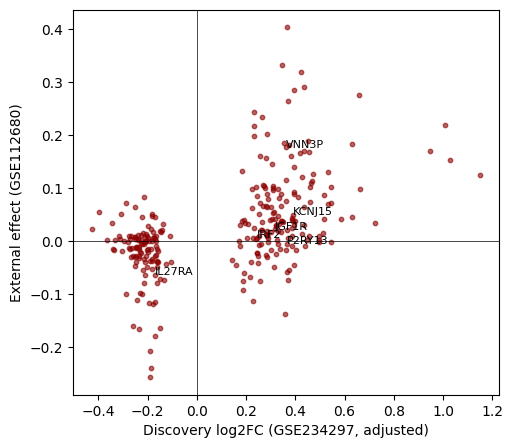

In [19]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

adj = pd.read_csv("GSE234297_DESeq2_adjusted_v2.txt", sep="\t", index_col=0); adj.index = adj.index.astype(str)
degs = adj.index[adj.padj < 0.05]

mm = meta.set_index("gsm").loc[G.columns]
keep = mm.diagnosis.isin(["ALS", "CON"]).to_numpy()
y = (mm.diagnosis[keep] == "ALS").astype(float).to_numpy()
sex = (mm.sex[keep] == "m").astype(float).to_numpy()
Y = G.loc[:, keep].to_numpy().T

def bh(p):
    n = len(p); o = np.argsort(p); r = p[o] * n / np.arange(1, n + 1)
    r = np.minimum.accumulate(r[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(r, 1); return out

def ols(extra):
    X = np.column_stack([np.ones(len(y)), y] + extra)
    B = np.linalg.lstsq(X, Y, rcond=None)[0]; R = Y - X @ B; df = len(y) - X.shape[1]
    se = np.sqrt((R ** 2).sum(0) / df * np.linalg.inv(X.T @ X)[1, 1])
    return pd.DataFrame({"effect": B[1], "p": 2 * stats.t.sf(abs(B[1] / se), df)}, index=G.index)

# 1. replication of the 324 DEGs
ext = ols([sex])
common = degs.intersection(ext.index)
d = adj.loc[common, "log2FoldChange"]; e = ext.loc[common]
same = (np.sign(d) == np.sign(e.effect))
print(f"DEGs measurable on the array: {len(common)} of {len(degs)}")
print(f"same direction: {int(same.sum())} ({same.mean():.0%}); sign test p = {stats.binomtest(int(same.sum()), len(common), 0.5).pvalue:.2g}")
print(f"Spearman, discovery log2FC vs external effect: {stats.spearmanr(d, e.effect)[0]:.2f}")
print(f"same direction AND BH < 0.05 within these genes: {int((same & (bh(e.p.to_numpy()) < 0.05)).sum())}")

hub = {"53829": "P2RY13", "3480": "IGF1R", "3772": "KCNJ15", "3660": "IRF2", "9466": "IL27RA", "55350": "VNN3P"}
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(d, e.effect, s=10, c="#8B0000", alpha=.6)
for g, s in hub.items():
    if g in common: ax.annotate(s, (d[g], e.effect[g]), fontsize=8)
ax.axhline(0, c="k", lw=.5); ax.axvline(0, c="k", lw=.5)
ax.set_xlabel("Discovery log2FC (GSE234297, adjusted)")
ax.set_ylabel("External effect (GSE112680)")

In [20]:
print(f"DEGs measurable on the array: {len(common)} of {len(degs)}")
print(f"same direction: {int(same.sum())} ({same.mean():.0%}); sign test p = {stats.binomtest(int(same.sum()), len(common), 0.5).pvalue:.2g}")
print(f"Spearman: {stats.spearmanr(d, e.effect)[0]:.2f}")
print(f"same direction AND BH < 0.05: {int((same & (bh(e.p.to_numpy()) < 0.05)).sum())}")
print("neutrophil score ALS vs control p:", stats.ttest_ind(neut[y == 1], neut[y == 0], equal_var=False)[1])
print(pd.DataFrame({"effect, sex only": ext.loc[list(hub)].effect, "effect, + composition": adj_ext.loc[list(hub)].effect,
                    "p, sex only": ext.loc[list(hub)].p, "p, + composition": adj_ext.loc[list(hub)].p}).rename(index=hub).round(4))

DEGs measurable on the array: 283 of 324
same direction: 201 (71%); sign test p = 1.1e-12
Spearman: 0.52
same direction AND BH < 0.05: 79


NameError: name 'neut' is not defined

In [21]:
def score(entrez):
    rows = [g for g in entrez if g in G.index]
    S = G.loc[rows, :].loc[:, keep]
    return ((S.sub(S.mean(axis=1), axis=0)).div(S.std(axis=1), axis=0)).mean(axis=0).to_numpy()

neut = score(["2215", "1441", "3579", "6279", "6280"])
tcell = score(["916", "915", "914", "3575"])
adj_ext = ols([sex, neut, tcell])

print("neutrophil score, ALS vs control p:", stats.ttest_ind(neut[y == 1], neut[y == 0], equal_var=False)[1])
print("DEGs with BH<0.05 externally, sex only -> sex + composition:",
      int((bh(ext.loc[common, "p"].to_numpy()) < 0.05).sum()), "->", int((bh(adj_ext.loc[common, "p"].to_numpy()) < 0.05).sum()))
print(pd.DataFrame({"effect, sex only": ext.loc[list(hub)].effect, "effect, + composition": adj_ext.loc[list(hub)].effect,
                    "p, sex only": ext.loc[list(hub)].p, "p, + composition": adj_ext.loc[list(hub)].p}).rename(index=hub).round(4))

neutrophil score, ALS vs control p: 2.3054921316728783e-13
DEGs with BH<0.05 externally, sex only -> sex + composition: 88 -> 65
        effect, sex only  effect, + composition  p, sex only  p, + composition
P2RY13           -0.0052                -0.0306       0.8338            0.2486
IGF1R             0.0224                -0.0308       0.1421            0.0572
KCNJ15            0.0499                -0.0299       0.0260            0.1155
IRF2              0.0070                -0.0604       0.6932            0.0012
IL27RA           -0.0636                -0.0614       0.0439            0.0563
VNN3P             0.1773                 0.1147       0.0000            0.0000
